# Módulo 2 · Introducción a la visualización de datos

**Notebook de práctica** · Escuela de Machine Learning Honduras 2026

1. ¿Por qué graficar? El cuarteto de Anscombe
2. Elegir la gráfica según la pregunta
3. matplotlib: anatomía de una gráfica
4. Los 4 tipos básicos: barras, líneas, dispersión, histograma
5. Distribuciones: histogramas y bins
6. Diagramas de caja: media vs. mediana
7. seaborn: gráficas estadísticas en una línea
8. plotly: gráficas interactivas
9. Gráficas que engañan
10. 🏆 Reto final

**Cómo usarlo:** corre las celdas en orden (`Shift + Enter`). En cada **✏️ Ejercicio** escribe tu código donde dice `# TU CÓDIGO AQUÍ`; la celda siguiente revisa tu gráfica y responde ✅ o ❌.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

plt.rcParams["figure.figsize"] = (6, 4)

# Función para revisar tus ejercicios: imprime ✅ o ❌ (nunca rompe el notebook)
def revisar(condicion, mensaje_ok="¡Correcto!", pista="Revisa tu código e inténtalo otra vez."):
    try:
        ok = bool(condicion() if callable(condicion) else condicion)
    except Exception as e:
        ok, pista = False, f"{pista}  (error: {type(e).__name__}: {e})"
    if ok and callable(mensaje_ok):
        mensaje_ok = mensaje_ok()
    print(("✅ " + mensaje_ok) if ok else ("❌ Aún no. " + pista))

# La tabla de 14 alumnos del curso (datos inventados)
import pandas as pd
import numpy as np

alumnos = pd.DataFrame({
    "nombre":       ["Luis", "Pedro", "Diego", "Carla", "Sofía", "Marta", "Jorge",
                     "Rosa", "Kevin", "Lucía", "Mario", "Elena", "Andrés", "Valeria"],
    "grupo":        ["A"] * 7 + ["B"] * 7,
    "horas":        [2, 3, 5, 6, 7, 8, 5, 4, 9, 7, 3, 7, 1, 8],
    "asistencia":   [60, 95, 70, 90, 75, 90, 90, 80, 65, 85, np.nan, 95, 90, 70],
    "calificacion": [4.5, 5.8, 5.5, 7.8, 7.2, 9.1, 7.0, 5.9, 8.0, 5.7, 5.1, 9.4, 4.2, 8.3],
    "aprobo":       [False, False, False, True, True, True, True,
                     False, True, False, False, True, False, True],
})
alumnos.to_csv("alumnos.csv", index=False)   # lo guardamos como archivo para practicar read_csv

df = pd.read_csv("alumnos.csv")

# Promedio semanal de cada grupo (8 semanas, datos inventados)
semanas = [1, 2, 3, 4, 5, 6, 7, 8]
prom_A = [6.1, 6.4, 6.3, 6.9, 7.2, 7.0, 7.5, 7.8]
prom_B = [5.8, 6.0, 6.6, 6.5, 6.8, 7.3, 7.4, 7.6]

# 200 calificaciones simuladas: dos grupos de alumnos (uno cerca de 5, otro cerca de 8)
rng = np.random.default_rng(7)
calificaciones = np.clip(np.concatenate([rng.normal(5, 1, 67), rng.normal(8, 0.9, 133)]), 0, 10).round(1)

print("¡Listo!", df.shape, len(calificaciones))

¡Listo! (14, 6) 200


## 1. ¿Por qué graficar? El cuarteto de Anscombe

Francis Anscombe (1973) construyó **cuatro conjuntos de datos** con casi las mismas estadísticas. seaborn trae una copia; si no hay internet, la celda usa los valores escritos a mano.

In [2]:
try:
    anscombe = sns.load_dataset("anscombe")
except Exception:
    x = [10, 8, 13, 9, 11, 14, 6, 4, 12, 7, 5]
    x4 = [8] * 7 + [19] + [8] * 3
    ys = {"I":  [8.04, 6.95, 7.58, 8.81, 8.33, 9.96, 7.24, 4.26, 10.84, 4.82, 5.68],
          "II": [9.14, 8.14, 8.74, 8.77, 9.26, 8.10, 6.13, 3.10, 9.13, 7.26, 4.74],
          "III":[7.46, 6.77, 12.74, 7.11, 7.81, 8.84, 6.08, 5.39, 8.15, 6.42, 5.73],
          "IV": [6.58, 5.76, 7.71, 8.84, 8.47, 7.04, 5.25, 12.50, 5.56, 7.91, 6.89]}
    anscombe = pd.concat([pd.DataFrame({"dataset": k, "x": x4 if k == "IV" else x, "y": v}) for k, v in ys.items()])

anscombe.groupby("dataset").agg(media_x=("x", "mean"), media_y=("y", "mean"),
                                var_y=("y", "var")).round(2)

,media_x,media_y,var_y
dataset,,,
I,9.0,7.5,4.13
II,9.0,7.5,4.13
III,9.0,7.5,4.12
IV,9.0,7.5,4.12


### ✏️ Ejercicio 1
Calcula la **correlación** entre `x` y `y` para cada conjunto y guárdala en `correlaciones` (una Series con 4 valores).

<details><summary>💡 Pista</summary>

`anscombe.groupby("dataset").apply(lambda g: g["x"].corr(g["y"]))`
</details>

In [3]:
correlaciones = anscombe.groupby("dataset").apply(lambda g: g["x"].corr(g["y"]))
correlaciones.round(3)

dataset
I      0.816
II     0.816
III    0.816
IV     0.817
dtype: float64

In [4]:
revisar(lambda: (abs(correlaciones - 0.816) < 0.01).all(), "¡Las cuatro correlaciones son ≈ 0.816!", "Agrupa por dataset y usa .corr().")

✅ ¡Las cuatro correlaciones son ≈ 0.816!


Ahora **mira** los datos. ¿Siguen pareciendo iguales?

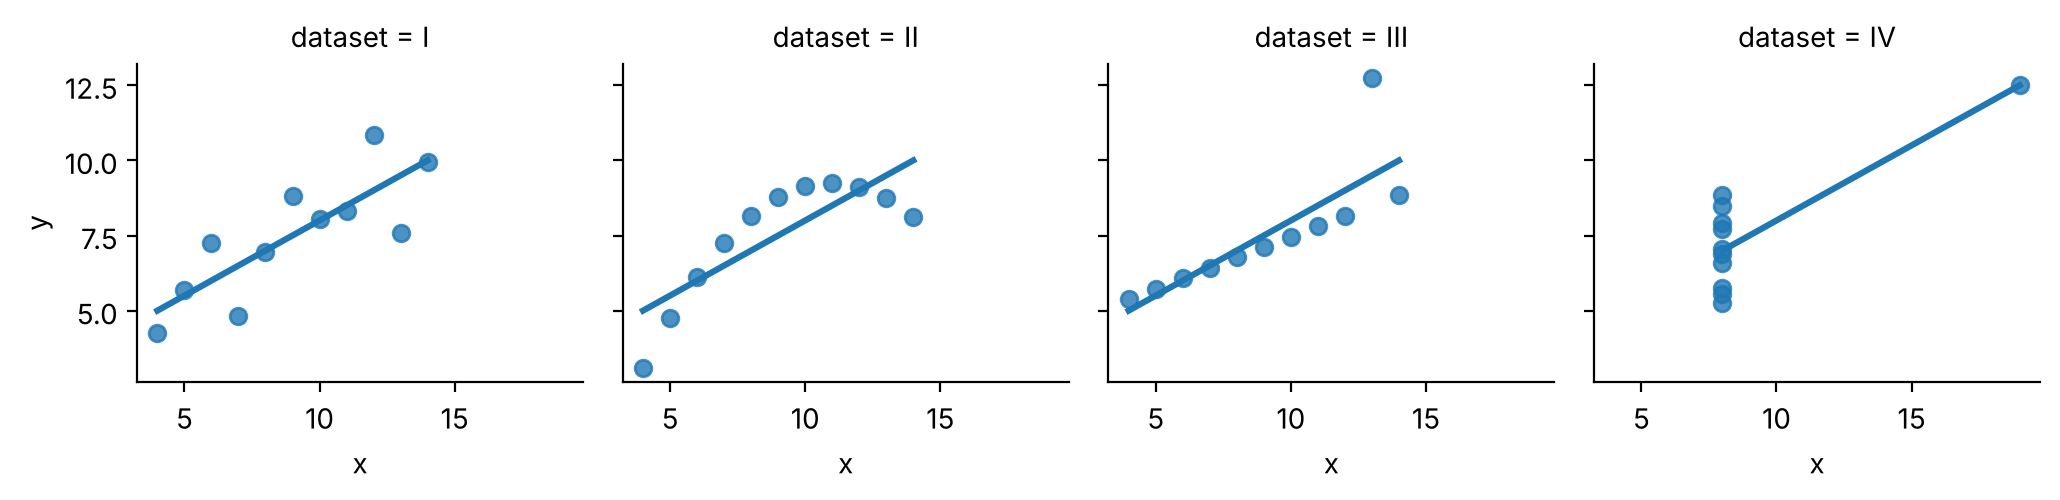

In [5]:
sns.lmplot(data=anscombe, x="x", y="y", col="dataset", col_wrap=4, height=2.6, ci=None)
plt.show()

> **Moraleja:** siempre grafica antes de confiar en un resumen numérico.

## 2. Elegir la gráfica según la pregunta

| Quiero mostrar… | Gráfica | matplotlib |
|---|---|---|
| **Comparar** categorías | barras | `plt.bar` / `plt.barh` |
| **Tendencia** en el tiempo | líneas | `plt.plot` |
| **Distribución** de una variable | histograma | `plt.hist` |
| **Relación** entre dos variables | dispersión | `plt.scatter` |
| **Comparar grupos** (distribuciones) | caja | `plt.boxplot` / `sns.boxplot` |

Nuestro ojo compara **posiciones y longitudes** mucho mejor que ángulos, áreas o colores. Por eso el pastel casi siempre pierde contra las barras.

### ✏️ Ejercicio 2 · ¿Qué gráfica usarías?
Escribe en el diccionario `respuestas` la gráfica adecuada para cada pregunta. Usa una de estas palabras: `"barras"`, `"lineas"`, `"histograma"`, `"dispersion"`, `"caja"`.

In [6]:
respuestas = {
    "¿Cómo cambió el promedio del grupo A semana a semana?": "lineas",
    "¿Qué alumno tuvo la calificación más alta?": "barras",
    "¿Más horas de estudio, mejor calificación?": "dispersion",
    "¿Cómo se reparten las 200 calificaciones?": "histograma",
    "¿El grupo A y el B se reparten distinto?": "caja",
}

In [7]:
correctas = ["lineas", "barras", "dispersion", "histograma", "caja"]
aciertos = sum(r == c for r, c in zip(respuestas.values(), correctas))
revisar(aciertos == 5, "5 de 5.", f"Llevas {aciertos} de 5. Revisa la tabla de arriba.")

✅ 5 de 5.


## 3. matplotlib: anatomía de una gráfica

- **Figura** (`fig`): el lienzo completo.
- **Ejes** (`ax`): el área donde se dibuja.
- **Título**, **etiquetas de los ejes** (con unidades), **leyenda**, **cuadrícula**.

Esta es la gráfica "cruda", tal como sale sin arreglar nada:

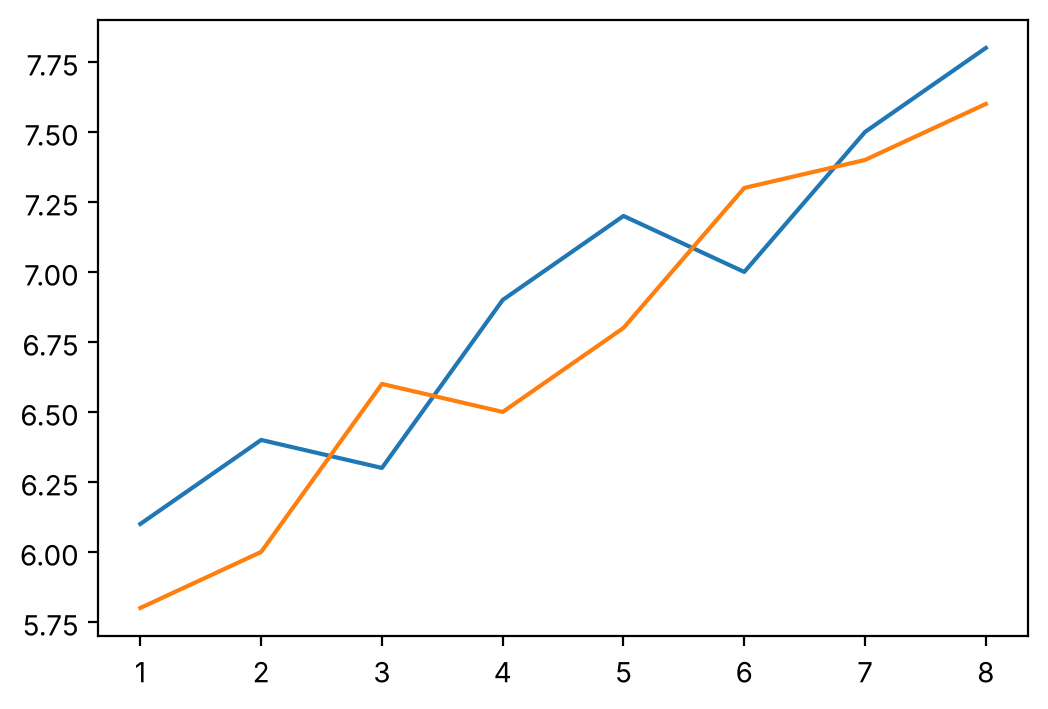

In [8]:
fig, ax = plt.subplots()
ax.plot(semanas, prom_A)
ax.plot(semanas, prom_B)
plt.show()

¿Qué es cada línea? ¿Qué mide el eje y? Imposible saberlo. Vamos a arreglarla.

### ✏️ Ejercicio 3 · Construye una buena gráfica
Partiendo de la gráfica cruda, agrega:

1. `marker="o"` y una etiqueta (`label=`) a cada línea: `"Grupo A"` y `"Grupo B"`.
2. Título: `"Promedio semanal por grupo"`.
3. Etiquetas: eje x `"Semana"` y eje y `"Calificación promedio"`.
4. La leyenda (`ax.legend()`) y una cuadrícula suave (`ax.grid(alpha=0.3)`).
5. Quita los bordes de arriba y la derecha: `ax.spines[["top", "right"]].set_visible(False)`.

Guarda los ejes en la variable `ax3`.

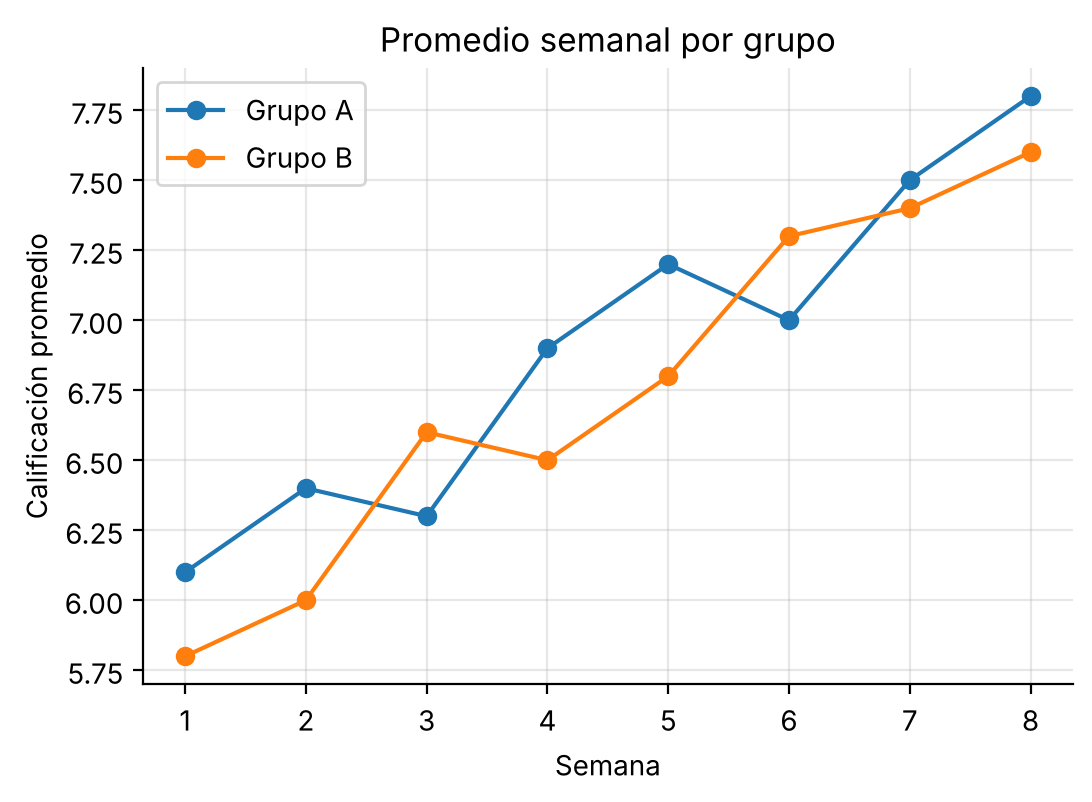

In [9]:
fig, ax3 = plt.subplots()
ax3.plot(semanas, prom_A, marker="o", label="Grupo A")
ax3.plot(semanas, prom_B, marker="o", label="Grupo B")
ax3.set_title("Promedio semanal por grupo")
ax3.set_xlabel("Semana")
ax3.set_ylabel("Calificación promedio")
ax3.legend()
ax3.grid(alpha=0.3)
ax3.spines[["top", "right"]].set_visible(False)
plt.show()

In [10]:
revisar(lambda: ax3.get_title() == "Promedio semanal por grupo", "Título correcto.", "Usa ax3.set_title(...).")
revisar(lambda: ax3.get_xlabel() == "Semana" and ax3.get_ylabel() == "Calificación promedio", "Ejes con nombre.", "Usa set_xlabel y set_ylabel.")
revisar(lambda: ax3.get_legend() is not None and [l.get_label() for l in ax3.get_lines()] == ["Grupo A", "Grupo B"],
        "Leyenda con Grupo A y Grupo B.", 'Agrega label="Grupo A" en plot y luego ax3.legend().')
revisar(lambda: all(l.get_marker() == "o" for l in ax3.get_lines()), "Marcadores en las dos líneas.", 'Agrega marker="o".')
revisar(lambda: not ax3.spines["top"].get_visible(), "Bordes quitados.", 'ax3.spines[["top", "right"]].set_visible(False)')

✅ Título correcto.
✅ Ejes con nombre.
✅ Leyenda con Grupo A y Grupo B.
✅ Marcadores en las dos líneas.
✅ Bordes quitados.


> `plt.title(...)` y `ax.set_title(...)` hacen lo mismo: son dos estilos. Con `ax` tienes más control cuando hay varias gráficas.

## 4. Los 4 tipos básicos

Siempre el mismo patrón: **datos en x**, **datos en y**, opciones (`color=`, `label=`, `marker=`, `alpha=`). Con `plt.subplots(1, 2)` dibujas dos gráficas lado a lado.

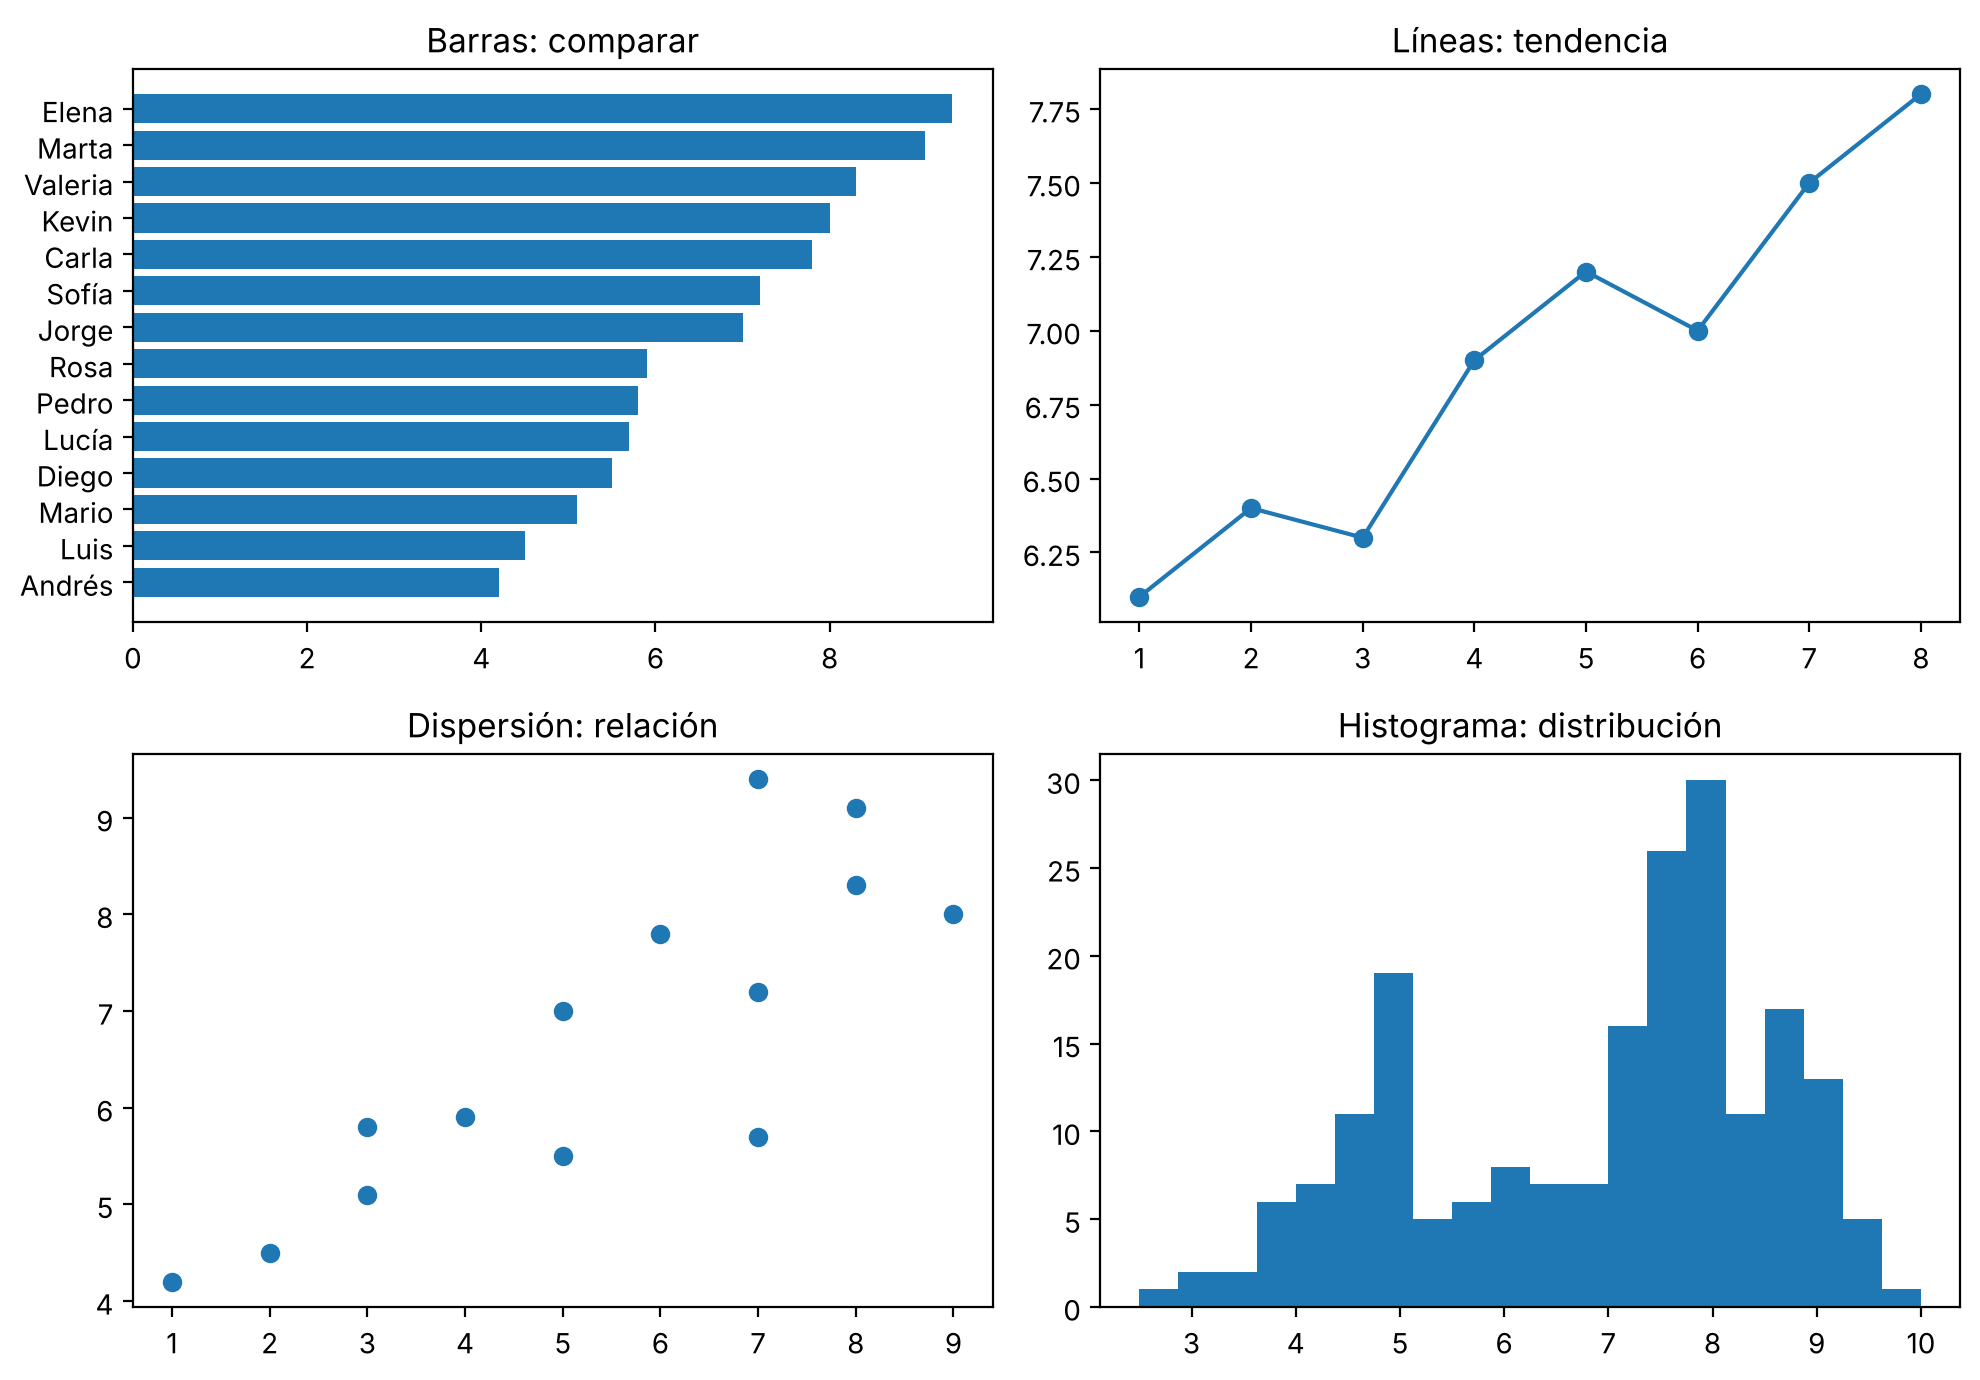

In [11]:
fig, axs = plt.subplots(2, 2, figsize=(10, 7))
orden = df.sort_values("calificacion")
axs[0, 0].barh(orden["nombre"], orden["calificacion"]);           axs[0, 0].set_title("Barras: comparar")
axs[0, 1].plot(semanas, prom_A, marker="o");                       axs[0, 1].set_title("Líneas: tendencia")
axs[1, 0].scatter(df["horas"], df["calificacion"]);                axs[1, 0].set_title("Dispersión: relación")
axs[1, 1].hist(calificaciones, bins=20);                           axs[1, 1].set_title("Histograma: distribución")
plt.tight_layout()
plt.show()

### ✏️ Ejercicio 4 · Barras ordenadas
Haz una gráfica de **barras horizontales** con la calificación de cada alumno, **ordenadas** de menor a mayor. Pinta de naranja (`"tab:orange"`) a quienes aprobaron y de azul (`"tab:blue"`) a quienes no. Agrega título y etiqueta del eje x. Guarda los ejes en `ax4`.

<details><summary>💡 Pista</summary>

```python
orden = df.sort_values("calificacion")
colores = ["tab:orange" if a else "tab:blue" for a in orden["aprobo"]]
ax4.barh(orden["nombre"], orden["calificacion"], color=colores)
```
</details>

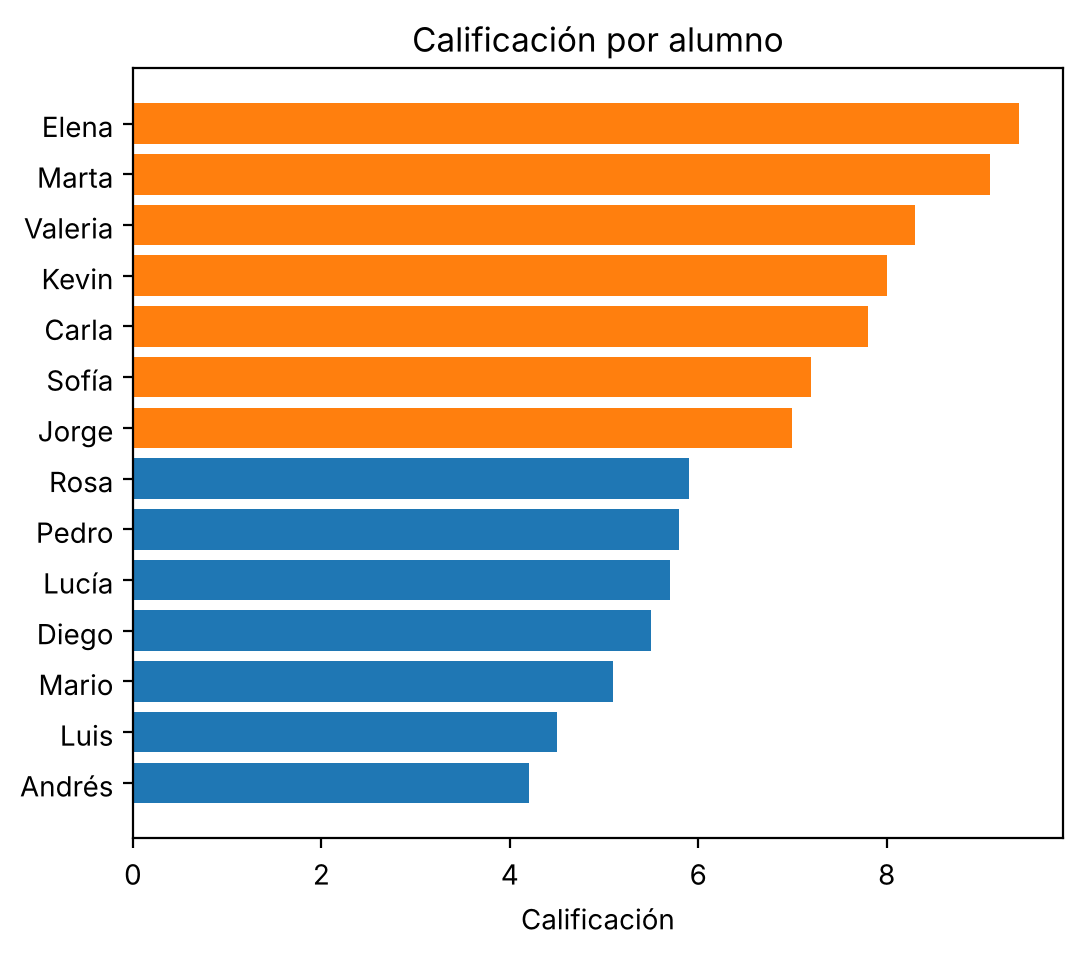

In [12]:
orden = df.sort_values("calificacion")
colores = ["tab:orange" if a else "tab:blue" for a in orden["aprobo"]]
fig, ax4 = plt.subplots(figsize=(6, 5))
ax4.barh(orden["nombre"], orden["calificacion"], color=colores)
ax4.set_title("Calificación por alumno")
ax4.set_xlabel("Calificación")
plt.show()

In [13]:
barras = ax4.patches
revisar(lambda: len(barras) == 14, "14 barras.", "Una barra por alumno con ax4.barh(...).")
revisar(lambda: len(barras) == 14 and [b.get_width() for b in barras] == sorted(b.get_width() for b in barras), "Barras ordenadas.", "Ordena antes con sort_values.")
revisar(lambda: len({b.get_facecolor() for b in barras}) == 2, "Dos colores según aprobó.", "Usa color=colores con una lista.")
revisar(lambda: ax4.get_title() != "" and ax4.get_xlabel() != "", "Título y etiqueta.", "Falta título o etiqueta del eje x.")

✅ 14 barras.
✅ Barras ordenadas.
✅ Dos colores según aprobó.
✅ Título y etiqueta.


### ✏️ Ejercicio 5 · Dispersión por grupo
Haz una gráfica de dispersión de `horas` (x) contra `calificacion` (y), dibujando **cada grupo con un color y su etiqueta** (`"Grupo A"`, `"Grupo B"`), con leyenda y ejes con nombre. Guarda los ejes en `ax5`.

<details><summary>💡 Pista</summary>

Un ciclo: `for g, datos in df.groupby("grupo"): ax5.scatter(datos["horas"], datos["calificacion"], label=f"Grupo {g}")`
</details>

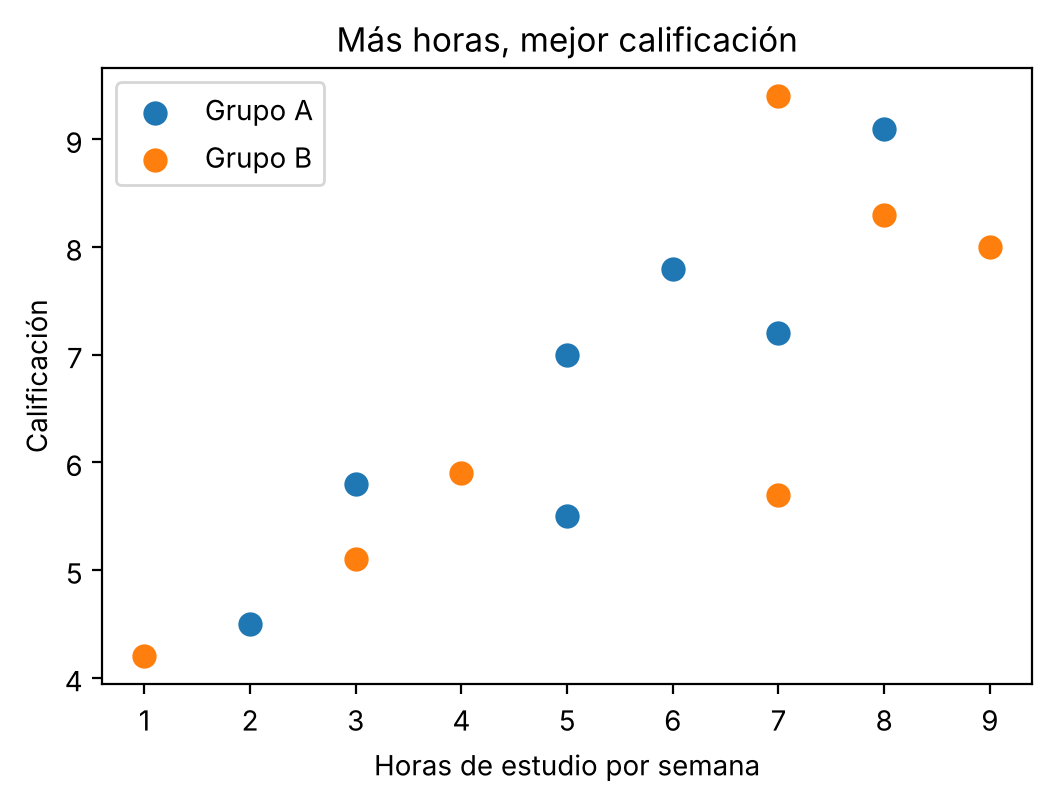

In [14]:
fig, ax5 = plt.subplots()
for g, datos in df.groupby("grupo"):
    ax5.scatter(datos["horas"], datos["calificacion"], label=f"Grupo {g}", s=60)
ax5.set_xlabel("Horas de estudio por semana")
ax5.set_ylabel("Calificación")
ax5.set_title("Más horas, mejor calificación")
ax5.legend()
plt.show()

In [15]:
revisar(lambda: len(ax5.collections) == 2 and ax5.get_legend() is not None, "Dos grupos con leyenda.", "Llama a scatter una vez por grupo y luego legend().")
revisar(lambda: ax5.get_xlabel() != "" and ax5.get_ylabel() != "", "Ejes con nombre.", "Agrega set_xlabel y set_ylabel.")

✅ Dos grupos con leyenda.
✅ Ejes con nombre.


## 5. Distribuciones: el número de bins importa

Un **histograma** cuenta cuántos valores caen en cada intervalo (*bin*). Con muy pocos bins se pierde la forma; con demasiados, solo se ve ruido.

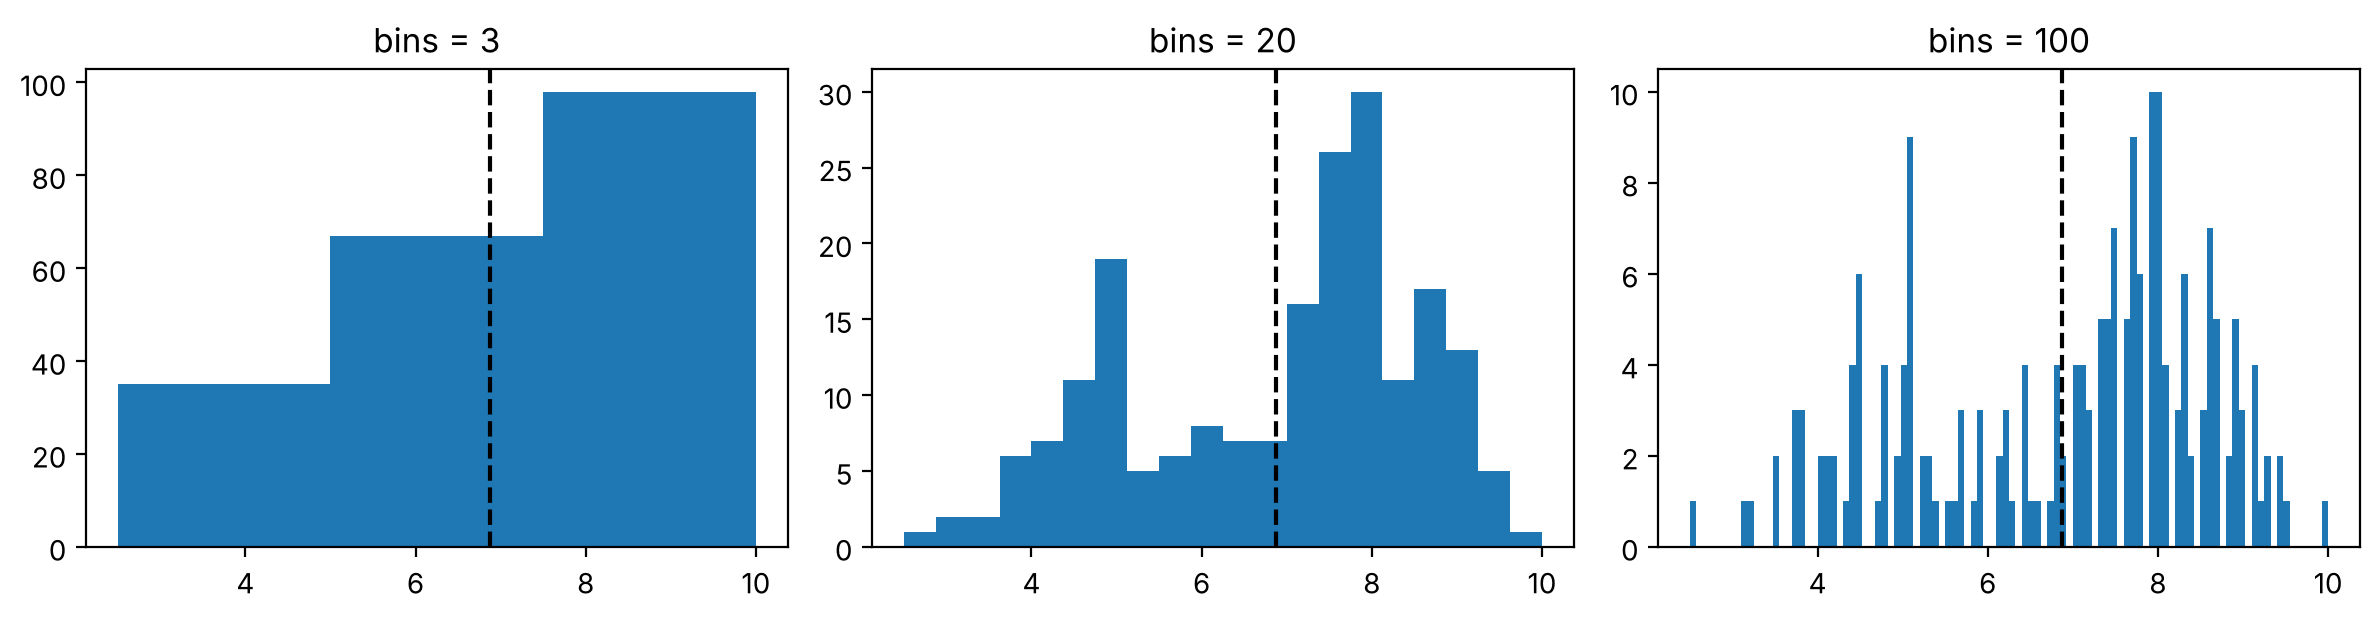

media = 6.87   mediana = 7.40


In [16]:
fig, axs = plt.subplots(1, 3, figsize=(12, 3.2), sharey=False)
for ax, b in zip(axs, [3, 20, 100]):
    ax.hist(calificaciones, bins=b, color="tab:blue")
    ax.axvline(calificaciones.mean(), color="k", ls="--")
    ax.set_title(f"bins = {b}")
plt.tight_layout()
plt.show()
print(f"media = {calificaciones.mean():.2f}   mediana = {np.median(calificaciones):.2f}")

Con 20 bins se ven **dos grupos** de alumnos: unos cerca de 5 y otros cerca de 8. La media (≈ 7) cae donde casi no hay nadie: **un solo número no describe esta distribución**.

### ✏️ Ejercicio 6
1. Haz un histograma de `calificaciones` con **10 bins**, título y etiqueta del eje x. Guarda los ejes en `ax6`.
2. Agrega una línea vertical roja en la **mediana** (`ax6.axvline(..., color="red")`).
3. Guarda en `mayor_que_6` la **proporción** de calificaciones mayores que 6 (un número entre 0 y 1).

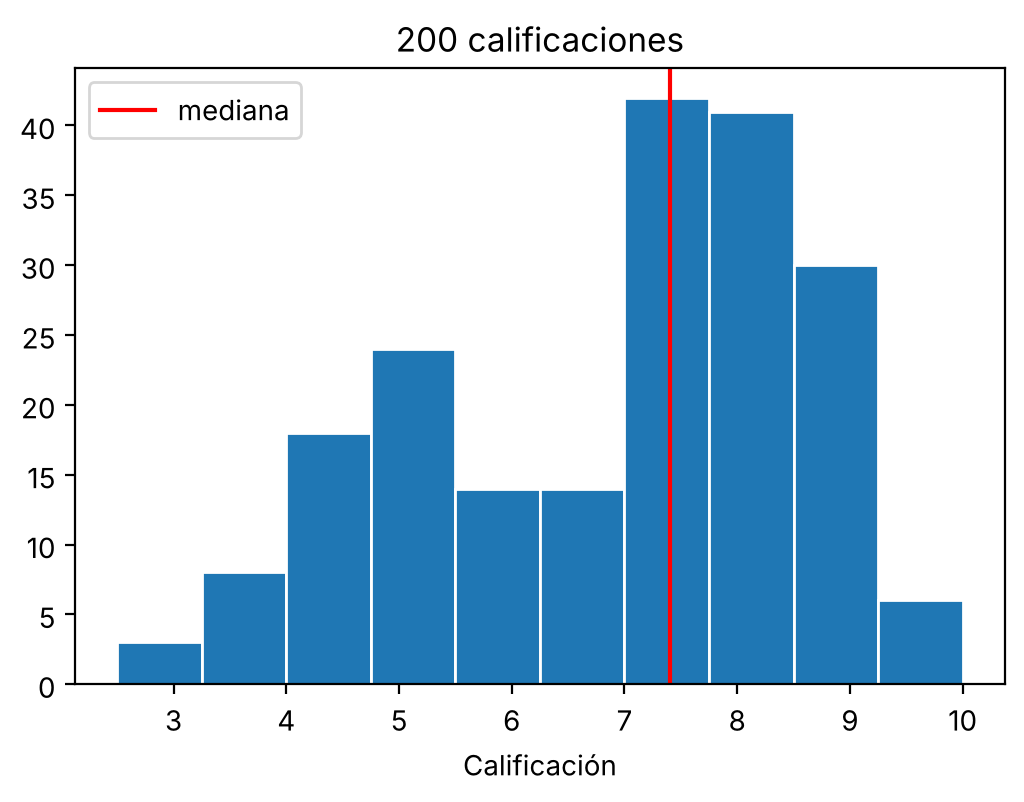

0.69


In [17]:
fig, ax6 = plt.subplots()
ax6.hist(calificaciones, bins=10, edgecolor="white")
ax6.axvline(np.median(calificaciones), color="red", label="mediana")
ax6.set_title("200 calificaciones")
ax6.set_xlabel("Calificación")
ax6.legend()
plt.show()
mayor_que_6 = (calificaciones > 6).mean()
print(mayor_que_6)

In [18]:
revisar(lambda: len(ax6.patches) == 10, "10 bins.", "plt.hist(..., bins=10)")
revisar(lambda: any(abs(l.get_xdata()[0] - np.median(calificaciones)) < 1e-9 for l in ax6.get_lines()), "Línea en la mediana.", "ax6.axvline(np.median(calificaciones), color='red')")
revisar(lambda: abs(mayor_que_6 - (calificaciones > 6).mean()) < 1e-9, f"Proporción = {(calificaciones > 6).mean():.2f}.", "(calificaciones > 6).mean() da la proporción.")

✅ 10 bins.
✅ Línea en la mediana.
✅ Proporción = 0.69.


## 6. Diagramas de caja: media vs. mediana

- **Mediana**: la mitad está abajo, la mitad arriba.
- **Caja**: del cuartil 1 (25 %) al cuartil 3 (75 %). **IQR** = Q3 − Q1.
- **Bigotes**: hasta el último dato a menos de 1.5·IQR de la caja.
- **Puntos sueltos**: posibles **valores atípicos**.

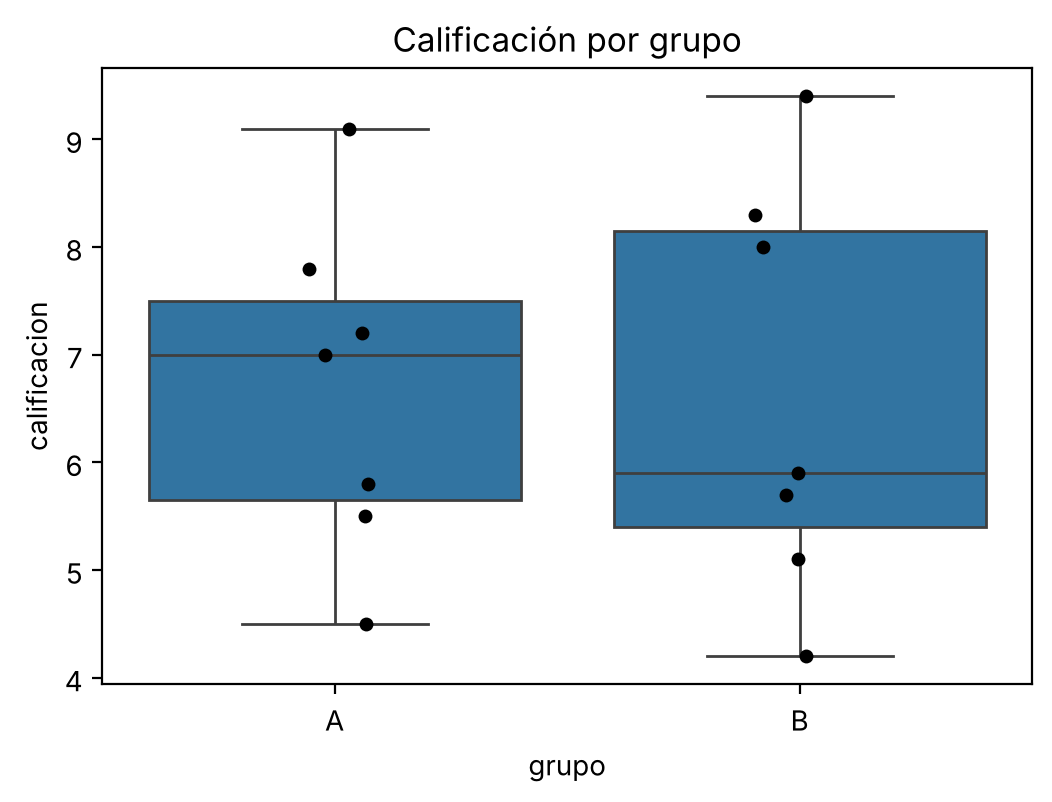

In [19]:
sns.boxplot(data=df, x="grupo", y="calificacion")
sns.stripplot(data=df, x="grupo", y="calificacion", color="k")
plt.title("Calificación por grupo")
plt.show()

### ✏️ Ejercicio 7 · Un error de captura
Marta (grupo A) tiene 9.1, pero alguien escribió **19.1** por error.

1. Copia las calificaciones del grupo A en `grupo_a` y cambia el 9.1 por 19.1 en `con_error`.
2. Calcula `media_antes`, `media_despues`, `mediana_antes` y `mediana_despues`.
3. Calcula `q1`, `q3`, el `iqr` y el límite `limite_sup = q3 + 1.5 * iqr` **con el error**. ¿Marta queda fuera?

<details><summary>💡 Pista</summary>

`np.percentile(con_error, 25)` da Q1; `np.mean`, `np.median` hacen el resto.
</details>

media: 6.70 → 8.13
mediana: 7.00 → 7.00
límite superior: 10.27  ¿19.1 es atípico? True


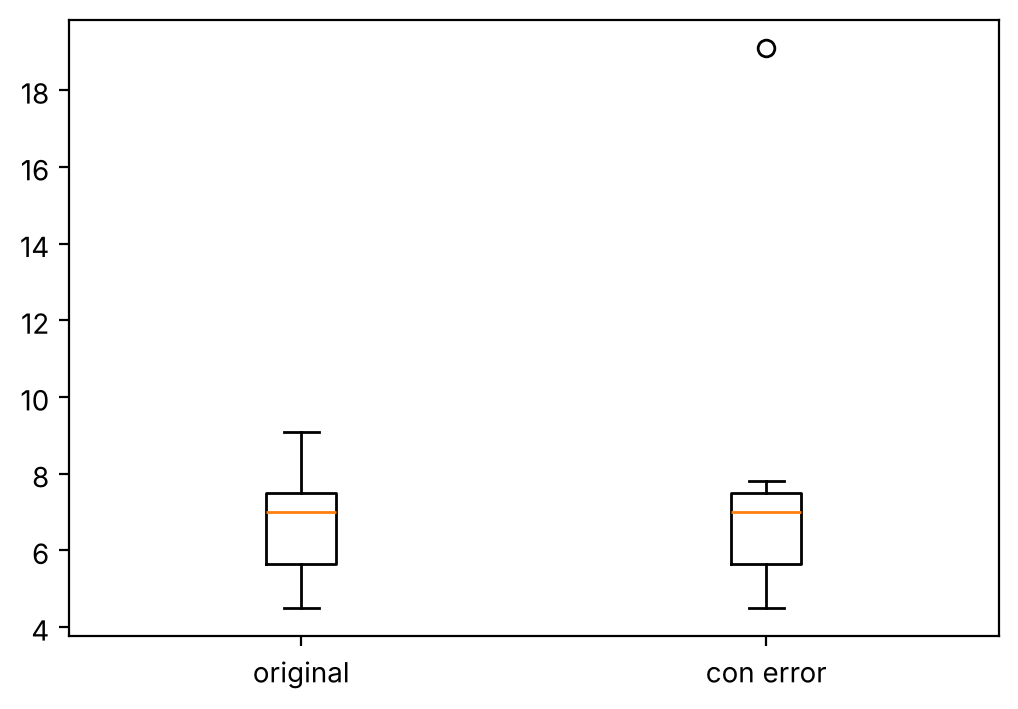

In [20]:
grupo_a = df[df["grupo"] == "A"]["calificacion"].to_numpy()
con_error = np.where(grupo_a == 9.1, 19.1, grupo_a)
media_antes, media_despues = grupo_a.mean(), con_error.mean()
mediana_antes, mediana_despues = np.median(grupo_a), np.median(con_error)
q1, q3 = np.percentile(con_error, 25), np.percentile(con_error, 75)
iqr = q3 - q1
limite_sup = q3 + 1.5 * iqr
print(f"media: {media_antes:.2f} → {media_despues:.2f}")
print(f"mediana: {mediana_antes:.2f} → {mediana_despues:.2f}")
print(f"límite superior: {limite_sup:.2f}  ¿19.1 es atípico? {19.1 > limite_sup}")
plt.boxplot([grupo_a, con_error], tick_labels=["original", "con error"])
plt.show()

In [21]:
revisar(lambda: abs(media_despues - media_antes - 10 / 7) < 1e-6, "La media subió 1.43 puntos por UN solo dato.", "media_despues debería ser la media de con_error.")
revisar(lambda: mediana_antes == mediana_despues == 7.0, "¡La mediana no se movió (7.0)!", "Usa np.median.")
revisar(lambda: 19.1 > limite_sup, "19.1 queda fuera de Q3 + 1.5·IQR: es atípico.", "Revisa q1, q3 e iqr.")

✅ La media subió 1.43 puntos por UN solo dato.
✅ ¡La mediana no se movió (7.0)!
✅ 19.1 queda fuera de Q3 + 1.5·IQR: es atípico.


> **Moraleja:** con datos que pueden tener errores o valores extremos, la **mediana** es más confiable que la media.

## 7. seaborn: gráficas estadísticas en una línea

seaborn se construye sobre matplotlib y trabaja directo con DataFrames: `data=df` y nombres de columna. Con `hue=` colorea por categoría y pone la leyenda solo.

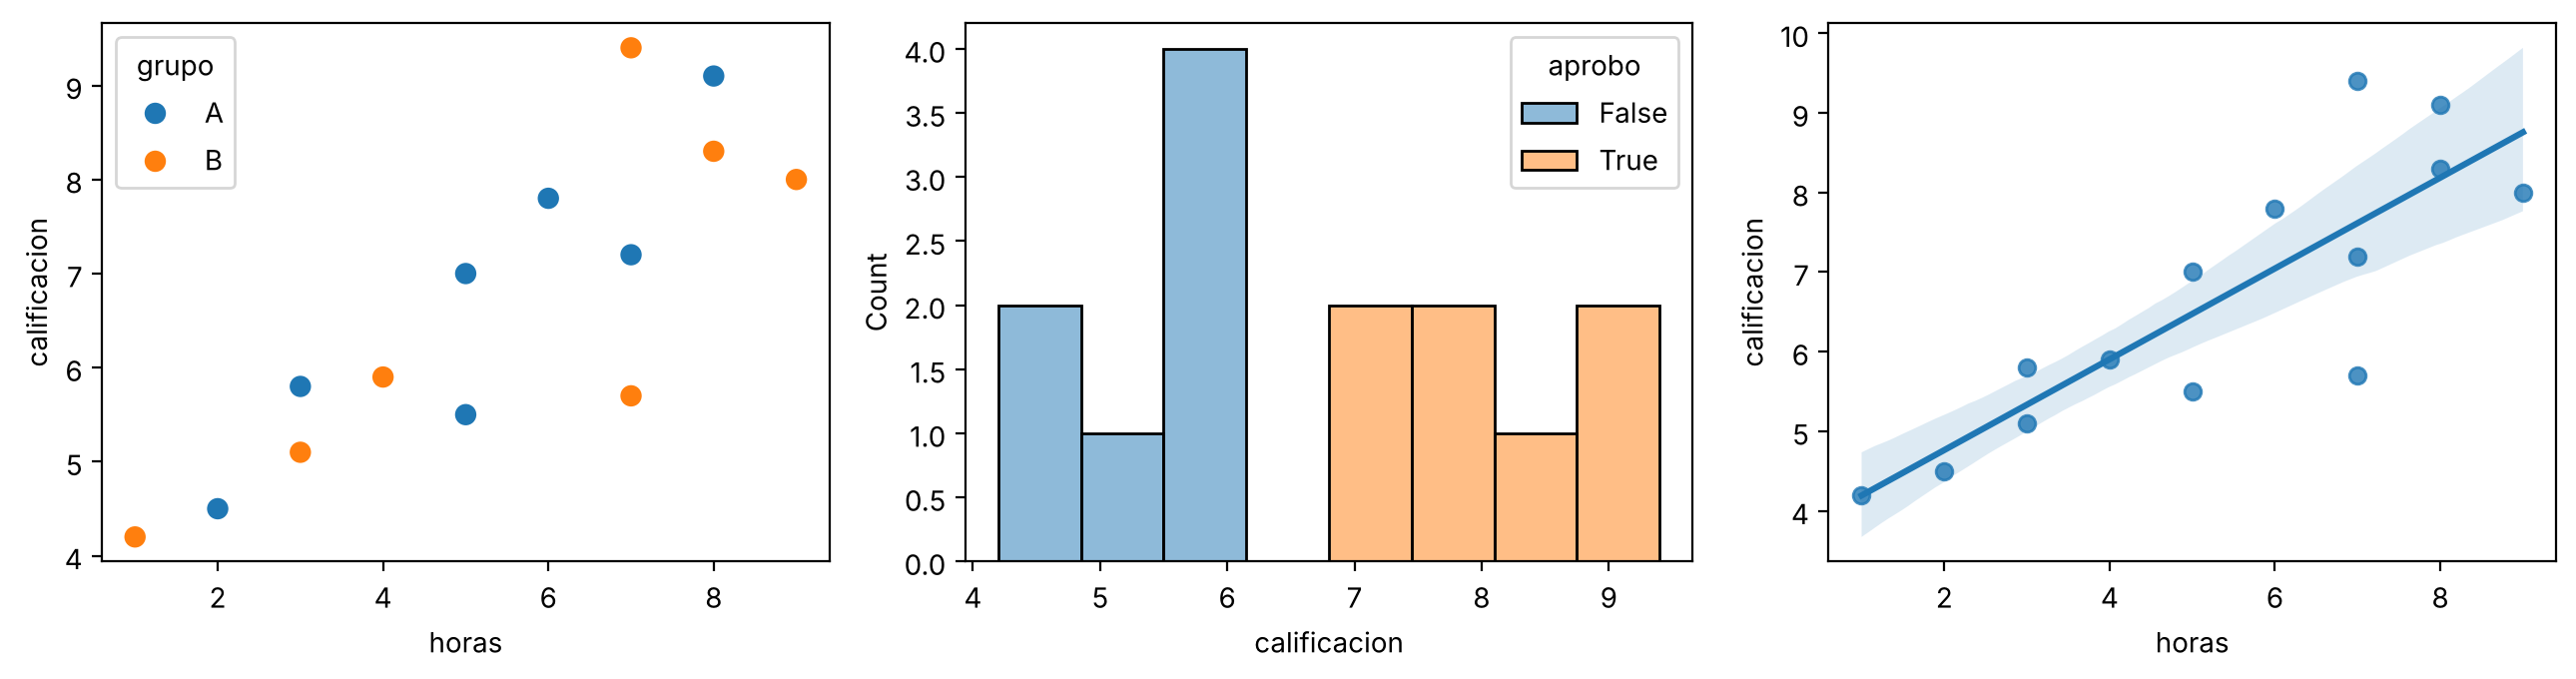

In [22]:
fig, axs = plt.subplots(1, 3, figsize=(13, 3.5))
sns.scatterplot(data=df, x="horas", y="calificacion", hue="grupo", s=70, ax=axs[0])
sns.histplot(data=df, x="calificacion", hue="aprobo", bins=8, ax=axs[1])
sns.regplot(data=df, x="horas", y="calificacion", ax=axs[2])
plt.tight_layout()
plt.show()

### ✏️ Ejercicio 8 · Correlaciones con un mapa de calor
1. Guarda en `corr` la matriz de correlación de las columnas numéricas `["horas", "asistencia", "calificacion"]` (`.corr()`).
2. Dibújala con `sns.heatmap(corr, annot=True, cmap="viridis", vmin=-1, vmax=1)`.
3. ¿Qué variable se relaciona más con la calificación? Guarda su nombre en `mas_relacionada`.

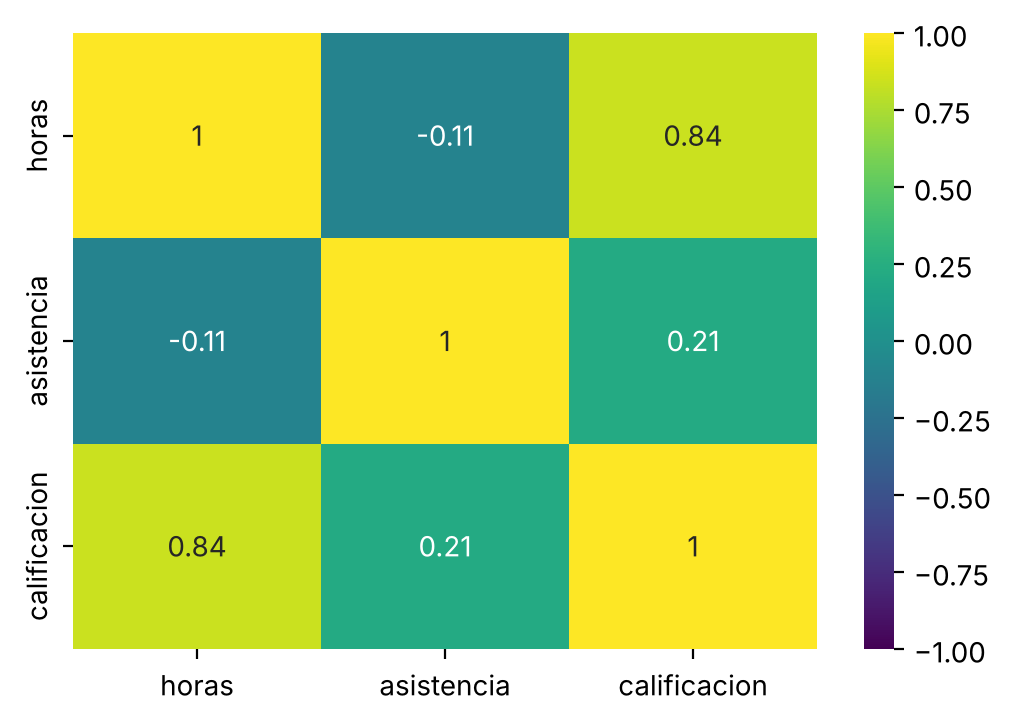

horas


In [23]:
corr = df[["horas", "asistencia", "calificacion"]].corr()
sns.heatmap(corr, annot=True, cmap="viridis", vmin=-1, vmax=1)
plt.show()
mas_relacionada = corr["calificacion"].drop("calificacion").idxmax()
print(mas_relacionada)

In [24]:
revisar(lambda: corr.shape == (3, 3), "Matriz de 3 × 3.", 'df[["horas", "asistencia", "calificacion"]].corr()')
revisar(lambda: mas_relacionada == "horas", "Las horas de estudio se relacionan más con la calificación.", "Mira la columna 'calificacion' del mapa.")

✅ Matriz de 3 × 3.
✅ Las horas de estudio se relacionan más con la calificación.


> ⚠️ **Correlación no es causalidad.** Que las horas y la calificación se muevan juntas no prueba que una cause la otra.

## 8. plotly: gráficas interactivas

Pasa el cursor sobre los puntos: verás el nombre de cada alumno. También puedes hacer zoom y apagar grupos dando clic en la leyenda.

In [25]:
fig = px.scatter(df, x="horas", y="calificacion", color="grupo", hover_name="nombre",
                 title="Horas vs. calificación (pasa el cursor)")
fig.show()

### ✏️ Ejercicio 9
Con `px.line`, grafica la tendencia semanal de los dos grupos de forma interactiva. Primero arma una tabla larga `tabla_semanas` con columnas `semana`, `grupo` y `promedio` (16 filas). Guarda la figura en `fig9`.

<details><summary>💡 Pista</summary>

```python
tabla_semanas = pd.DataFrame({"semana": semanas * 2,
                              "grupo": ["A"] * 8 + ["B"] * 8,
                              "promedio": prom_A + prom_B})
fig9 = px.line(tabla_semanas, x="semana", y="promedio", color="grupo", markers=True)
```
</details>

In [26]:
tabla_semanas = pd.DataFrame({"semana": semanas * 2,
                              "grupo": ["A"] * 8 + ["B"] * 8,
                              "promedio": prom_A + prom_B})
fig9 = px.line(tabla_semanas, x="semana", y="promedio", color="grupo", markers=True,
               title="Promedio semanal por grupo")
fig9.show()

In [27]:
revisar(lambda: tabla_semanas.shape[0] == 16 and set(tabla_semanas.columns) >= {"semana", "grupo", "promedio"}, "Tabla larga correcta.", "16 filas: 8 semanas × 2 grupos.")
revisar(lambda: len(fig9.data) == 2, "Dos líneas interactivas.", 'px.line(..., color="grupo")')

✅ Tabla larga correcta.
✅ Dos líneas interactivas.


## 9. Gráficas que engañan

En barras, la **longitud** representa el valor. Si el eje y no empieza en 0, una diferencia pequeña parece enorme.

**Factor de mentira** (Edward Tufte) = tamaño del efecto en la gráfica / tamaño del efecto en los datos. Lo honesto es ≈ 1.

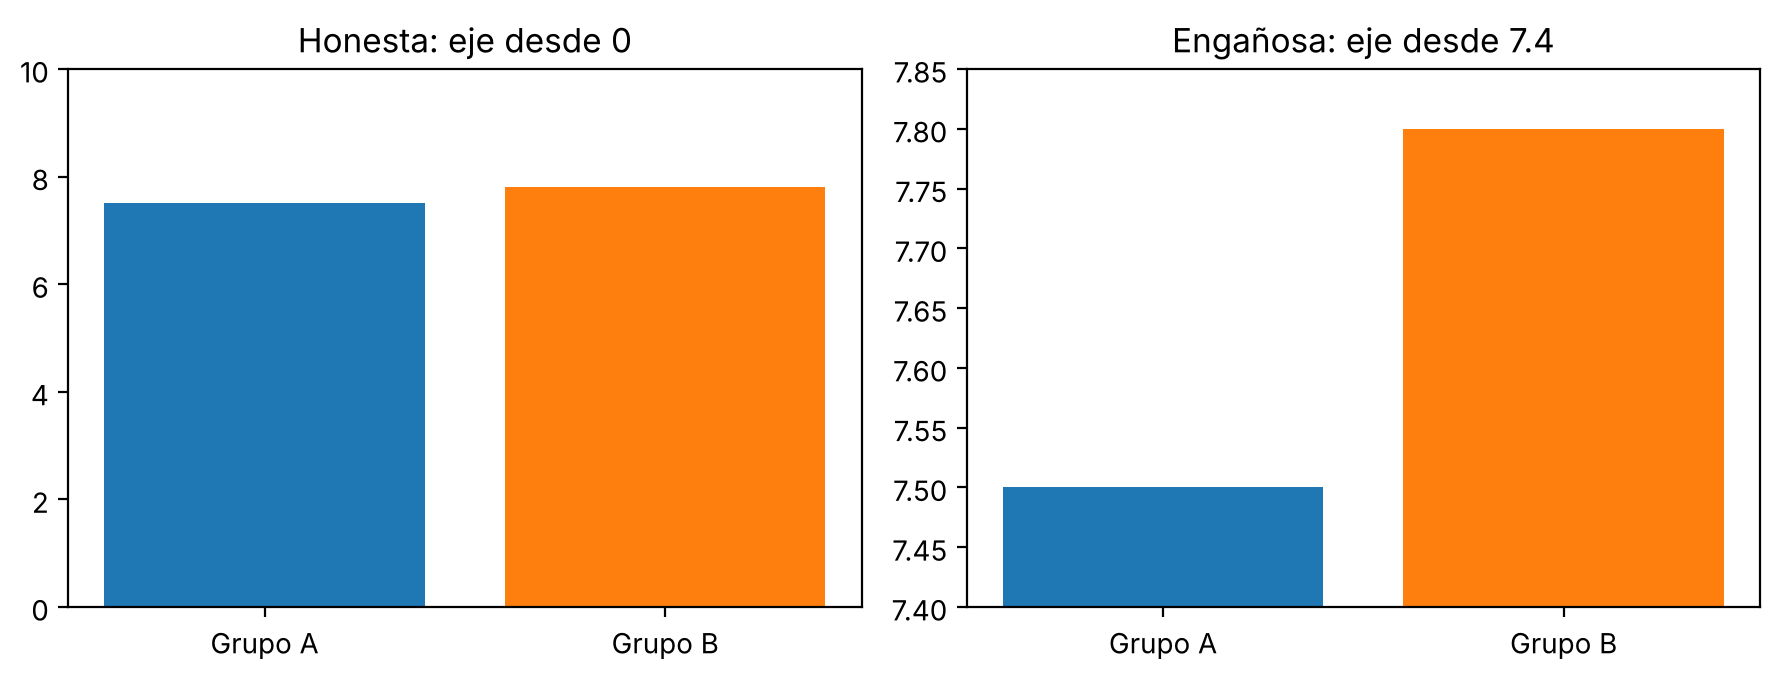

In [28]:
a, b = 7.5, 7.8
fig, axs = plt.subplots(1, 2, figsize=(9, 3.5))
axs[0].bar(["Grupo A", "Grupo B"], [a, b], color=["tab:blue", "tab:orange"]); axs[0].set_ylim(0, 10)
axs[0].set_title("Honesta: eje desde 0")
axs[1].bar(["Grupo A", "Grupo B"], [a, b], color=["tab:blue", "tab:orange"]); axs[1].set_ylim(7.4, 7.85)
axs[1].set_title("Engañosa: eje desde 7.4")
plt.tight_layout()
plt.show()

### ✏️ Ejercicio 10 · Calcula el factor de mentira
1. `efecto_real`: diferencia relativa en los datos, `(b - a) / a`.
2. `efecto_visto`: diferencia relativa de las **alturas dibujadas** cuando el eje empieza en `y0 = 7.4`: `((b - y0) - (a - y0)) / (a - y0)`.
3. `factor`: `efecto_visto / efecto_real`.

In [29]:
y0 = 7.4
efecto_real = (b - a) / a
efecto_visto = ((b - y0) - (a - y0)) / (a - y0)
factor = efecto_visto / efecto_real
print(f"real {efecto_real:.1%}, se ve {efecto_visto:.0%}, factor de mentira = {factor:.0f}")

real 4.0%, se ve 300%, factor de mentira = 75


In [30]:
revisar(lambda: abs(factor - 75) < 0.5, "¡Factor de mentira = 75! Una diferencia de 4 % se ve como de 300 %.", "Revisa las tres fórmulas.")

✅ ¡Factor de mentira = 75! Una diferencia de 4 % se ve como de 300 %.


### Lista de verificación de una buena gráfica
- ✅ Título que dice la **conclusión** ("El grupo B mejoró más"), no solo el tema.
- ✅ Ejes con nombre y unidades. Barras desde 0. Barras ordenadas por valor.
- 🎨 Color con propósito; paletas aptas para daltonismo (`viridis`, `sns.color_palette("colorblind")`).
- ❌ Sin 3D, sombras ni decoración que no informa.

## 10. 🏆 Reto final: un mini reporte

Crea **una sola figura** con dos gráficas lado a lado (`fig, (axA, axB) = plt.subplots(1, 2, figsize=(11, 4))`):

1. **Izquierda (`axA`)**: diagrama de caja de la `asistencia` por `grupo` (puedes usar `sns.boxplot(..., ax=axA)`).
2. **Derecha (`axB`)**: dispersión de `asistencia` vs. `calificacion` con color según `aprobo`.
3. Cada gráfica con un **título que diga una conclusión** y ejes con nombre.
4. Guarda la figura como `reporte.png` con `fig.savefig("reporte.png", dpi=150, bbox_inches="tight")`.

> Recuerda que Mario tiene la asistencia vacía (NaN): pandas y seaborn la omiten al graficar.

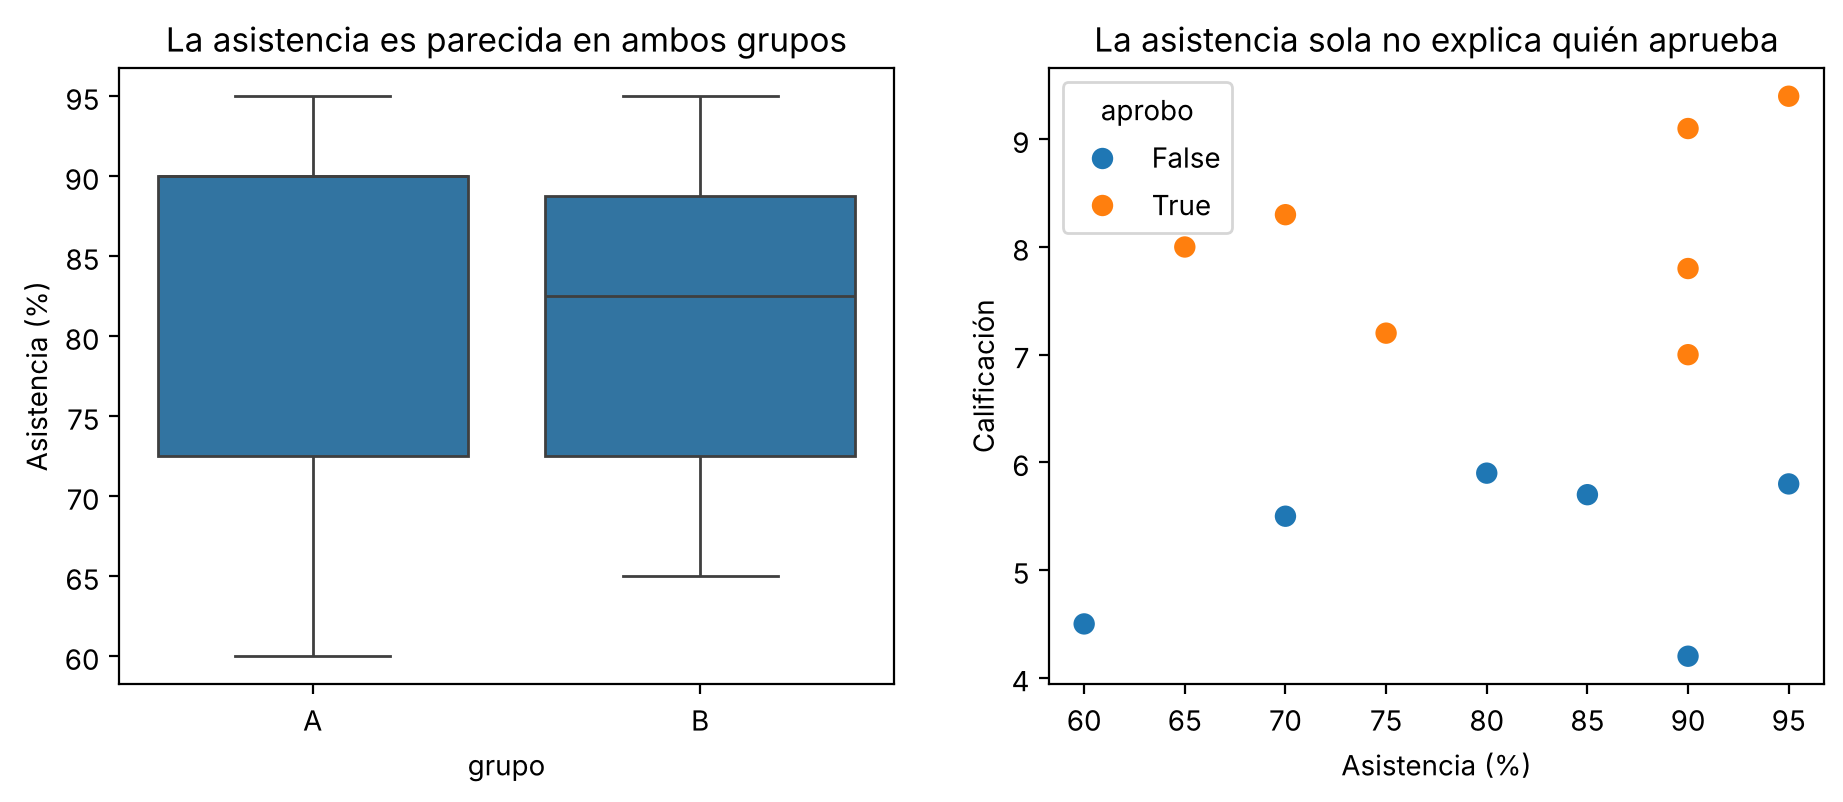

In [31]:
fig, (axA, axB) = plt.subplots(1, 2, figsize=(11, 4))
sns.boxplot(data=df, x="grupo", y="asistencia", ax=axA)
axA.set_title("La asistencia es parecida en ambos grupos")
axA.set_ylabel("Asistencia (%)")
sns.scatterplot(data=df, x="asistencia", y="calificacion", hue="aprobo", s=70, ax=axB)
axB.set_title("La asistencia sola no explica quién aprueba")
axB.set_xlabel("Asistencia (%)"); axB.set_ylabel("Calificación")
fig.savefig("reporte.png", dpi=150, bbox_inches="tight")
plt.show()

In [32]:
import os
revisar(lambda: axA.get_title() != "" and axB.get_title() != "", "Las dos gráficas tienen título.", "Pon un título a cada una.")
revisar(lambda: os.path.exists("reporte.png"), "reporte.png guardado (búscalo en la carpeta 📁 de la izquierda).", "Usa fig.savefig(...).")

✅ Las dos gráficas tienen título.
✅ reporte.png guardado (búscalo en la carpeta 📁 de la izquierda).


---
### 🎉 ¡Terminaste!
Ya sabes elegir una gráfica según la pregunta, construirla con matplotlib, explorar distribuciones, usar seaborn y plotly, y detectar gráficas engañosas.